# 11. 모델 비교 (1): 전체 기간 성능 — 학습 / 검증 / 테스트

10개 딥러닝 모델 × 3개 입력세트(A: 유역평균 강우, B: 관측소별 강우 7개, C: A+B)로 용담댐 시간 유입량을 예측한 결과를
**전체 기간 지표** 로 비교합니다. 홍수 첨두 재현은 `12_Comparison_Peaks.ipynb` 에서 따로 다룹니다.

각 모델의 학습·평가는 모델별 노트북(`01_…` ~ `10_…`)에서 이루어지며, 이 노트북은 `results/<model>_<set>/` 에 저장된 결과만 읽습니다.

| # | 모델 | `model` 키 | 계열 | 한 줄 요약 | 노트북 |
|---|---|---|---|---|---|
| 01 | LSTM | `cudalstm` | 순환(게이트) | 표준 LSTM(cuDNN 구현). 강우를 시간 순서대로 읽어 셀 상태에 유역 저류를 기억하는 기준(baseline) 모델. | `01_LSTM.ipynb` |
| 02 | GRU | `gru` | 순환(게이트) | LSTM보다 게이트가 하나 적은 경량 순환 모델. 셀 상태 없이 은닉 상태만으로 저류를 표현. | `02_GRU.ipynb` |
| 03 | Transformer | `transformer` | 주의(트랜스포머) | 자기주의(self-attention) 인코더. 720시간 창의 모든 시각 쌍을 직접 비교해 중요한 강우 시점을 가중. | `03_Transformer.ipynb` |
| 04 | MTS-LSTM | `mtslstm` | 순환(다중 시간규모) | 일 단위 LSTM이 365일을 읽은 뒤 상태를 시간 단위 LSTM 가지에 넘겨 최근 14일을 시간 해상도로 처리하는 다중 시간규모 LSTM. | `04_MTSLSTM.ipynb` |
| 05 | MC-LSTM | `mclstm` | 순환(질량보존) | 질량보존 LSTM. 강우(mm/h)를 질량으로 받아 셀에 저장·재분배·방출하므로 입력 강우량을 초과하는 유출을 낼 수 없음. | `05_MCLSTM.ipynb` |
| 06 | ODE-LSTM | `odelstm` | 순환(연속시간) | LSTM 은닉 상태를 상미분방정식(ODE)으로 연속시간 전개. 불규칙·다중 해상도 입력을 하나의 연속 상태로 처리. | `06_ODELSTM.ipynb` |
| 07 | Mamba | `mamba` | 상태공간(SSM) | 선택적 상태공간모델(SSM). 입력에 따라 변하는 상태전이로 긴 시퀀스를 선형 시간에 처리. | `07_Mamba.ipynb` |
| 08 | xLSTM | `x_lstm` | 순환(확장 LSTM) | 확장 LSTM. 지수 게이트와 행렬 메모리(mLSTM)·스칼라 메모리(sLSTM) 블록을 쌓아 LSTM의 저장 용량과 병렬성을 개선. | `08_xLSTM.ipynb` |
| 09 | PeakFocus | `peakfocus` | 주의(첨두 과제 결합) | 첨두 위치 분류(MSM-PL)와 유량 회귀를 함께 학습하고, 위치 인식 디코더(LAD)가 첨두 특징으로 교차주의를 게이팅. | `09_PeakFocus.ipynb` |
| 10 | Exformer | `exformer` | 주의(희소·패치 트랜스포머) | 극한 적응 트랜스포머. 패치 단위 희소 주의(국소+주기+극한 마스크)와 계절/추세 분해로 극한 강우 패치를 서로 연결. | `10_Exformer.ipynb` |

**연구 설정 요약**

| 항목 | 내용 |
|---|---|
| 대상 | 용담댐 (유역면적 930.42 km²) 시간 유입량 (m³/s) |
| 기간 | 2006-01-01 ~ 2025-12-31 (20년, 175,320 시간) |
| 학습 / 검증 / 테스트 | 2006–2017 (12년) / 2018–2021 (4년) / 2022–2025 (4년) |
| 입력세트 A | 유역평균 강수량 `rf_avg` (1변수) |
| 입력세트 B | 관측소별 강수량 `rf_<관측소>` × 7 (7변수) |
| 입력세트 C | A + B (8변수) |
| 해상도 | 시간(hourly). MTS-LSTM만 일(daily) 강우를 추가로 사용 |
| 공통 학습 설정 | Adam, lr 1e-3, batch 256, MSE, seq_length 720 h, epoch 30–50 (early stopping patience 5), seed 111 |
| 평가 epoch | 검증 loss가 최소인 epoch (early stopping은 학습을 멈출 뿐 가중치를 되돌리지 않음) |
| 데이터셋 클래스 | `hourlycsv` (`data/YDDam_paper/`) — `prepare_data.py` 로 생성 |
| 설정 파일 | `configs/<model>_<set>.yml` — `make_configs.py` 로 생성 |
| 공통 코드 | `common.py` (run 관리·평가·그림), `model_docs.py` (모델 설명) |



In [1]:
%matplotlib inline
import sys, warnings
warnings.filterwarnings("ignore", message=".*IProgress.*")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

sys.path.insert(0, str(Path.cwd()))
import common
from common import SETS, MODEL_NAME, MODEL_COLOR, SET_COLOR, SET_STYLE, PERIODS, PERIOD_LABEL
from model_docs import MODEL_DOCS, MODEL_FAMILY

warnings.filterwarnings("ignore", category=FutureWarning)
common.set_plot_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

from make_configs import MODEL_ORDER
results = common.collect_results()
models = [m for m in MODEL_ORDER if m in set(results["model"])]
missing = [m for m in MODEL_ORDER if m not in models]
print(f"{len(models)} models with results; missing: {missing}")
rain = common.load_rainfall(["rf_avg"])["rf_avg"]
preds = {(m, s): common.load_saved_predictions(m, s) for m in models for s in SETS if common.load_summary(m, s)}
summaries = {(m, s): common.load_summary(m, s) for m in models for s in SETS if common.load_summary(m, s)}
# input set with the highest test NSE for every model -> used when one line per model is drawn
best_set = {m: max(SETS, key=lambda s: summaries[(m, s)]["metrics"]["test"]["NSE"]) for m in models}
label = {m: f"{MODEL_NAME[m]} ({best_set[m]})" for m in models}
best_set

10 models with results; missing: []


{'lstm': 'A',
 'gru': 'A',
 'transformer': 'A',
 'mtslstm': 'C',
 'mclstm': 'A',
 'odelstm': 'B',
 'mamba': 'A',
 'xlstm': 'B',
 'peakfocus': 'B',
 'exformer': 'C'}

## 1. 모델 규모와 학습 비용

파라미터 수, 학습한 epoch 수, 최적 epoch, epoch당 시간, 총 학습 시간입니다. 같은 `hidden_size`(64)라도 구조에 따라 파라미터 수와
시간이 크게 다릅니다. (시간은 RTX 5090 Laptop GPU 기준, 서브프로세스 1개 또는 3개 동시 실행.)

In [2]:
cost = results[results["period"] == "test"].pivot_table(
    index="model_name", columns="set", values=["n_parameters", "epochs_trained", "best_epoch", "epoch_time_mean_s", "train_time_total_s"],
    observed=True)
cost = cost.reindex(columns=pd.MultiIndex.from_product([["n_parameters", "epochs_trained", "best_epoch", "epoch_time_mean_s", "train_time_total_s"], SETS]))
cost["train_time_total_s"] = cost["train_time_total_s"] / 60
cost = cost.rename(columns={"train_time_total_s": "train_time_min"}, level=0)
display(cost.round(1))
cost.round(1).to_csv(common.RESULTS_DIR / "comparison_cost.csv")

n_parameters                     epochs_trained             best_epoch             epoch_time_mean_s               train_time_min              
                       A         B         C              A     B     C          A     B     C                 A      B      C              A      B      C
model_name                                                                                                                                                 
LSTM             17217.0   18753.0   19009.0           37.0  42.0  50.0       22.0  37.0  45.0               8.2   10.8   11.1            5.1    7.6    9.3
GRU              12929.0   14081.0   14273.0           50.0  49.0  36.0       47.0  44.0  28.0               8.9   16.1   17.6            7.4   13.2   10.5
Transformer      67137.0   67521.0   67585.0           48.0  36.0  45.0       43.0   4.0   5.0             113.0  126.3  114.2           89.6   75.4   86.0
MTS-LSTM         42754.0   45826.0   46338.0           50.0  50.0  50.0       49.0  49.0  50.0               2.5    2.3    1.5            2.1    2.0    1.3
MC-LSTM         283008.0  308352.0  312576.0           50.0  44.0  50.0       49.0  39.0  49.0             752.7  768.3  758.8          630.2  566.1  632.8
ODE-LSTM         25537.0   27073.0   27329.0           50.0  50.0  45.0       49.0  49.0  40.0              26.0   27.1   32.0           21.7   22.7   23.9
Mamba            32833.0   33217.0   33281.0           36.0  45.0  38.0       24.0   1.0   4.0              33.9   33.4   35.9           20.4   25.2   22.9
xLSTM            63945.0   64329.0   64393.0           42.0  41.0  36.0       27.0  24.0  29.0             157.6  155.1  155.5          110.4  106.0   93.3
PeakFocus        92762.0   95066.0   95450.0           37.0  37.0  44.0       21.0  17.0  17.0              19.6   21.8   20.3           12.2   13.5   15.0
Exformer        382779.0  402960.0  402960.0           39.0  36.0  36.0        9.0   9.0  11.0              25.7   50.3   47.1           17.1   30.1   28.5

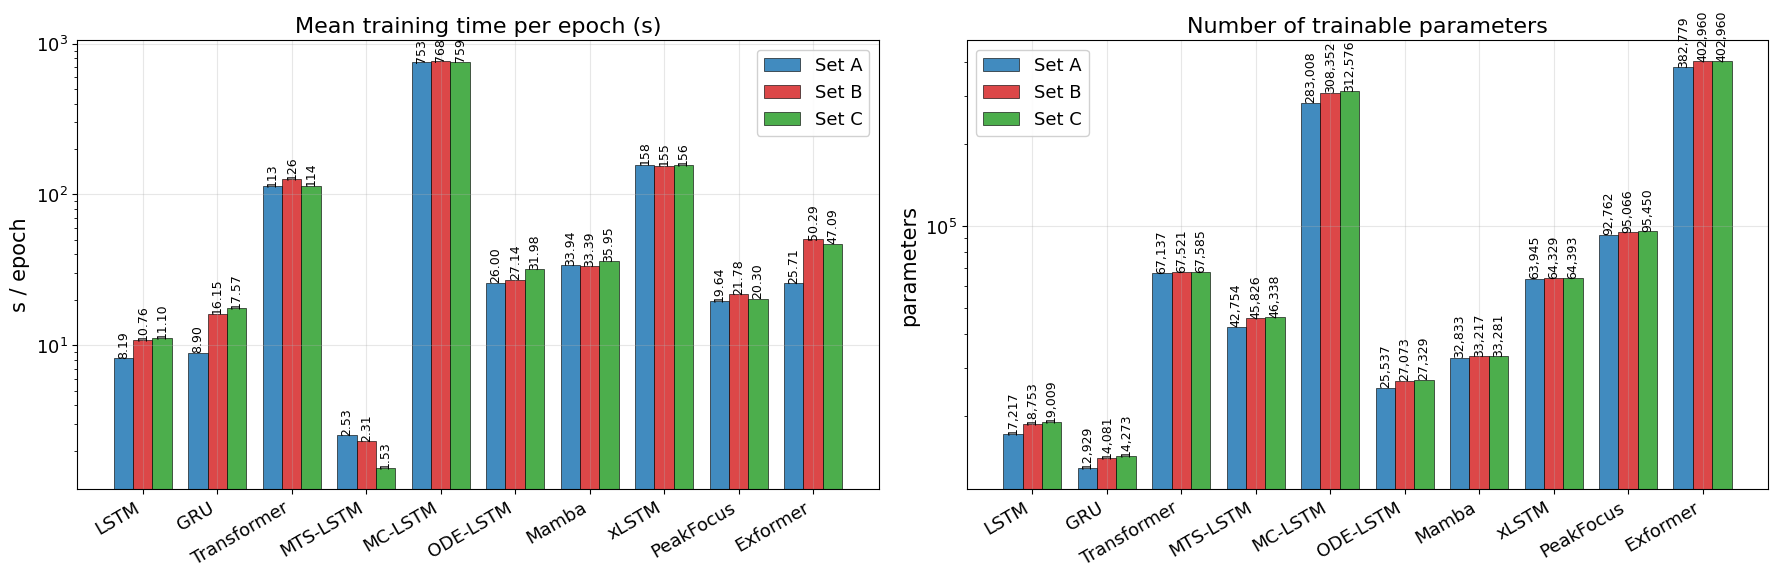

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
common.plot_metric_bars(results, "epoch_time_mean_s", period="test", ax=axes[0], title="Mean training time per epoch (s)")
axes[0].set_ylabel("s / epoch")
axes[0].set_yscale("log")
common.plot_metric_bars(results, "n_parameters", period="test", ax=axes[1], title="Number of trainable parameters")
axes[1].set_yscale("log")
axes[1].set_ylabel("parameters")
fig.tight_layout()
common.save_fig(fig, "cmp_cost")
plt.show()

## 2. 전체 기간 지표 (학습 / 검증 / 테스트)

행 = 모델, 열 = 지표 × 입력세트. 굵은 숫자 비교는 아래 히트맵이 더 편합니다.
모든 값은 시간 단위 m³/s 기준이며 `results/comparison_metrics_<period>.csv` 로 저장합니다.

In [4]:
tables = {}
for p in PERIODS:
    tables[p] = common.metric_table(results, p, metrics=("NSE", "KGE", "RMSE", "PBIAS", "FHV", "FLV"))
    tables[p].round(3).to_csv(common.RESULTS_DIR / f"comparison_metrics_{p}.csv")
    print(f"=== {PERIOD_LABEL[p]} ===")
    display(tables[p].round(3))

=== train (2006-2017) ===


NSE                  KGE                  RMSE                   PBIAS                     FHV                      FLV                  
                 A      B      C      A      B      C       A       B       C       A       B       C       A       B       C        A        B        C
model_name                                                                                                                                              
LSTM         0.929  0.947  0.947  0.926  0.927  0.964  19.094  16.673  16.674  -5.827  -5.033   0.896  -1.790  -3.858  -0.479   99.847   74.812 -132.777
GRU          0.934  0.943  0.935  0.941  0.969  0.899  18.540  17.223  18.465  -0.657   1.182   9.581  -3.514   1.405   2.200   79.206 -131.529 -133.372
Transformer  0.596  0.385  0.386  0.556  0.323  0.335  45.679  56.767  56.687 -21.377  41.184 -27.709 -22.584 -24.134 -39.076   98.300   95.710   93.087
MTS-LSTM     0.794  0.814  0.814  0.690  0.758  0.728  32.088  30.624  30.598  -8.630  -1.600   1.968 -18.442 -11.040 -15.893   99.848 -133.309 -135.016
MC-LSTM      0.636  0.583  0.672  0.624  0.360  0.567  43.404  46.834  41.503 -27.900 -57.326 -36.296 -11.406 -18.715 -13.759 -246.279 -772.078 -499.547
ODE-LSTM     0.548  0.584  0.558  0.523  0.532  0.522  47.529  45.747  47.151  -3.705 -11.584  -5.407 -29.676 -28.648 -28.521   94.392 -126.390   95.117
Mamba        0.897  0.737  0.834  0.875  0.705  0.823  23.126  37.125  29.465  -0.612  -2.803   1.029 -10.532 -21.850 -12.473 -132.045 -127.337 -128.112
xLSTM        0.926  0.944  0.949  0.956  0.933  0.959  19.493  17.114  16.346   2.335   6.105   1.840   0.198  -1.150  -3.699   97.010 -133.914 -133.185
PeakFocus    0.688  0.792  0.857  0.497  0.699  0.914  40.156  33.017  27.374  44.453  24.740  -0.448  19.033  13.493   6.131   96.907 -122.714 -114.703
Exformer     0.678  0.879  0.902  0.550  0.938  0.944  40.770  25.183  22.608  -1.931  -0.431  -2.535 -36.112   3.122  -0.251 -124.645 -113.178 -109.462

=== validation (2018-2021) ===


NSE                  KGE                  RMSE                   PBIAS                     FHV                     FLV                  
                 A      B      C      A      B      C       A       B       C       A       B       C       A       B       C       A        B        C
model_name                                                                                                                                             
LSTM         0.891  0.869  0.872  0.842  0.776  0.838  38.652  42.363  41.854  -8.940 -10.519  -3.792  -3.703 -12.030  -5.135  99.877  -68.932  -70.260
GRU          0.892  0.825  0.823  0.843  0.801  0.771  38.536  48.969  49.204  -6.325  -1.862   1.550  -7.374  -7.026 -10.468  85.256  -69.310   91.204
Transformer  0.532  0.275  0.304  0.527  0.207  0.224  80.099  99.616  97.617 -17.818  20.911 -25.285 -18.329 -53.010 -52.118  98.821   97.116   94.197
MTS-LSTM     0.667  0.664  0.672  0.558  0.578  0.575  67.532  67.876  67.021 -14.252  -9.947  -6.988 -25.164 -22.568 -24.820  99.887  -70.266  -71.488
MC-LSTM      0.735  0.660  0.680  0.615  0.347  0.494  60.197  68.283  66.190 -28.447 -56.705 -37.582 -17.638 -25.547 -22.280 -24.639 -523.460 -141.594
ODE-LSTM     0.438  0.450  0.432  0.353  0.365  0.358  87.771  86.829  88.230 -14.838 -20.249 -15.447 -46.890 -42.352 -43.984  98.001   73.774   96.734
Mamba        0.849  0.802  0.795  0.920  0.769  0.896  45.426  52.130  53.016   0.194  -5.486   0.483  -4.999 -19.037  -4.996 -69.044  -66.844  -67.281
xLSTM        0.887  0.888  0.885  0.881  0.844  0.847  39.333  39.158  39.758  -3.665  -1.992  -3.570  -3.678  -7.195  -6.731  98.181  -70.997  -70.614
PeakFocus    0.635  0.646  0.624  0.628  0.755  0.793  70.768  69.619  71.814  32.834  15.279  -2.722   7.737  -1.445  -1.664  97.982  -62.993  -57.205
Exformer     0.522  0.687  0.673  0.362  0.612  0.579  80.924  65.486  66.879 -21.939 -18.508 -21.367 -51.723 -24.864 -29.769 -50.811  -39.730  -32.822

=== test (2022-2025) ===


NSE                  KGE                  RMSE                   PBIAS                     FHV                      FLV                  
                 A      B      C      A      B      C       A       B       C       A       B       C       A       B       C        A        B        C
model_name                                                                                                                                              
LSTM         0.932  0.917  0.907  0.937  0.877  0.871  22.668  24.977  26.405   2.692   2.874  10.095  -1.381  -7.796  -0.748   99.844   97.785 -185.941
GRU          0.911  0.903  0.868  0.887  0.855  0.789  25.904  26.985  31.450   5.799   9.893  17.996  -6.257  -2.502  -1.676   96.700 -184.339   78.101
Transformer  0.559  0.169  0.222  0.715  0.104  0.179  57.509  78.984  76.442  -2.343  43.533 -23.559   0.003 -44.940 -53.148   97.827   95.385   89.000
MTS-LSTM     0.805  0.787  0.806  0.706  0.720  0.718  38.292  39.992  38.158   0.093   5.014   9.721 -18.676 -14.492 -14.550   99.825 -185.995 -188.069
MC-LSTM      0.692  0.576  0.672  0.741  0.420  0.639  48.125  56.427  49.641 -17.652 -50.726 -28.162  -6.375 -14.126  -9.088 -297.950 -990.837 -611.378
ODE-LSTM     0.555  0.580  0.541  0.505  0.532  0.501  57.794  56.151  58.700   4.846  -1.360   2.849 -37.341 -33.237 -35.270   94.755   94.167   96.246
Mamba        0.843  0.740  0.828  0.834  0.723  0.798  34.380  44.152  35.894  14.697   7.963  11.984   3.848 -16.491  -7.900 -184.721 -180.252 -180.779
xLSTM        0.894  0.939  0.932  0.892  0.865  0.891  28.196  21.465  22.644   9.477  12.699  10.043   0.449  -2.389  -1.071   96.332 -187.148 -186.461
PeakFocus    0.612  0.682  0.646  0.414  0.630  0.790  53.995  48.851  51.544  53.872  33.625  11.940  18.348   6.518   5.881   97.329 -172.457 -162.809
Exformer     0.553  0.699  0.705  0.444  0.660  0.625  57.901  47.514  47.062  -2.193  -2.368  -6.933 -46.771 -25.167 -30.224 -159.841 -143.169 -137.636

### 2.1 NSE / KGE 히트맵 (모델 × 입력세트 × 기간)

초록일수록 좋습니다. 가로 방향으로 보면 입력세트의 효과, 세로 방향으로 보면 모델의 효과, 기간 블록을 비교하면 일반화(과적합) 정도를 알 수 있습니다.

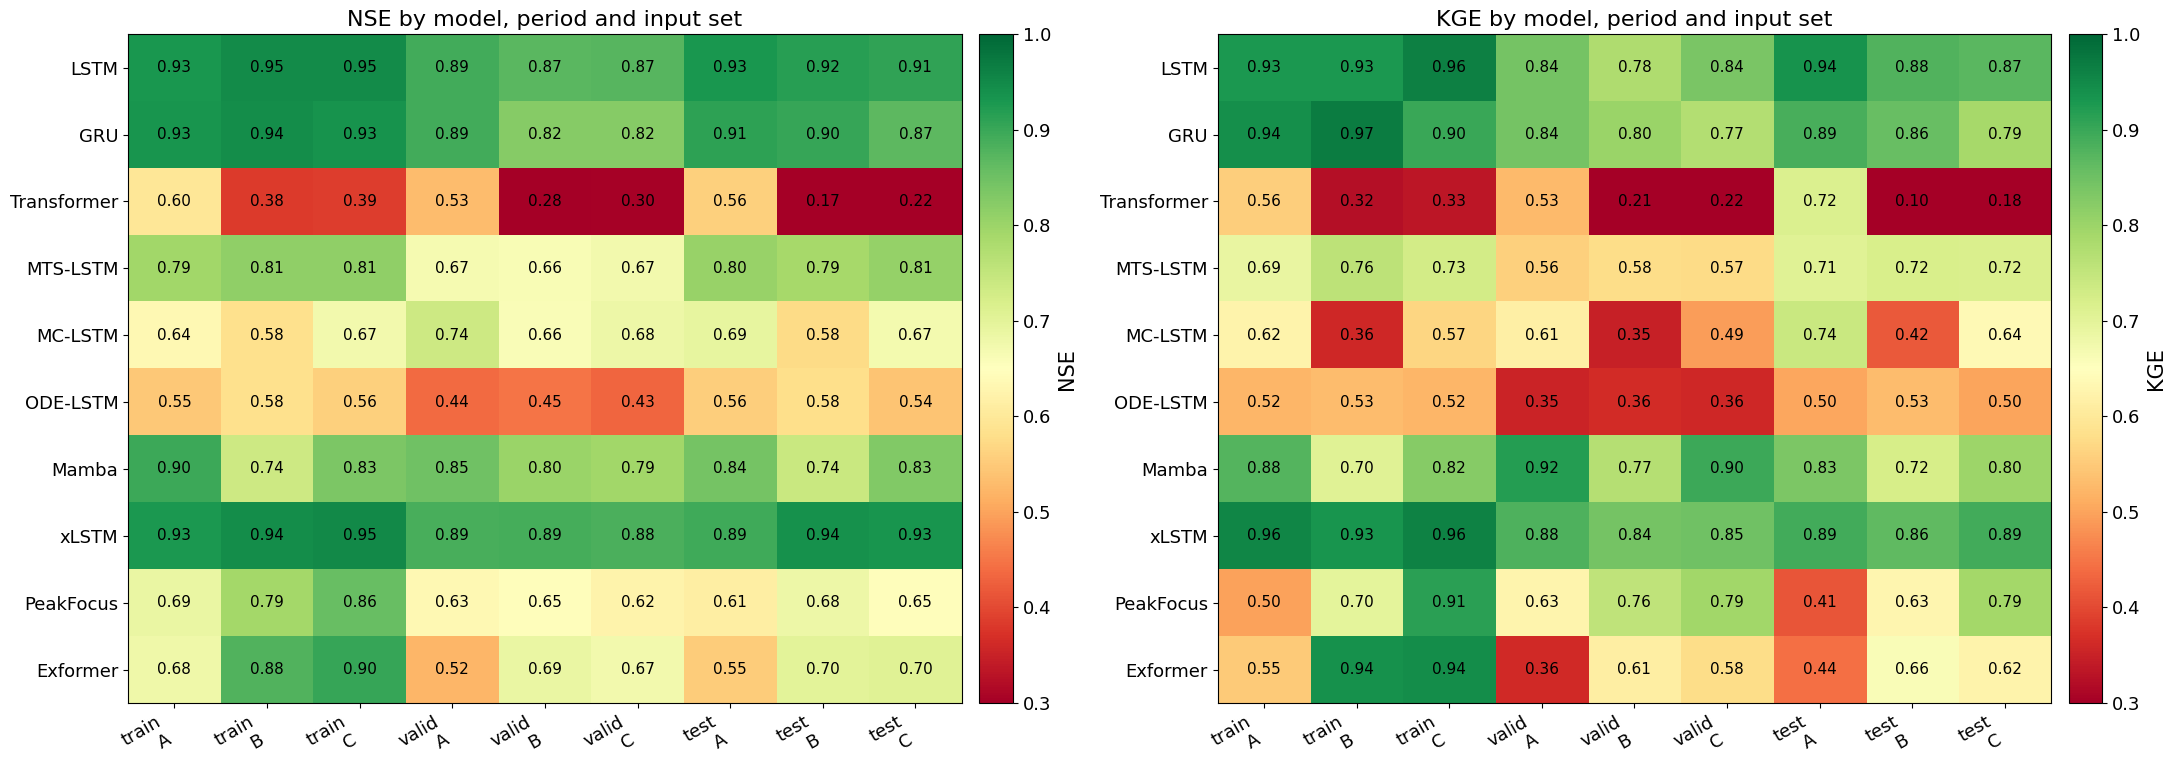

In [5]:
def period_set_table(metric):
    t = results.pivot_table(index="model_name", columns=["period", "set"], values=metric, observed=True)
    return t.reindex(columns=pd.MultiIndex.from_product([list(PERIODS), SETS]))

fig, axes = plt.subplots(1, 2, figsize=(22, 8))
for ax, metric in zip(axes, ["NSE", "KGE"]):
    t = period_set_table(metric)
    t.columns = [f"{p[:5]}\n{s}" for p, s in t.columns]
    common.plot_heatmap(t, title=f"{metric} by model, period and input set", vmin=0.3, vmax=1.0, ax=ax, cbar_label=metric)
fig.tight_layout()
common.save_fig(fig, "cmp_heatmap_nse_kge")
plt.show()

### 2.2 테스트 기간 막대그래프

NSE, KGE, RMSE, PBIAS 의 테스트 기간 값입니다. 점선은 이상값(1 또는 0).

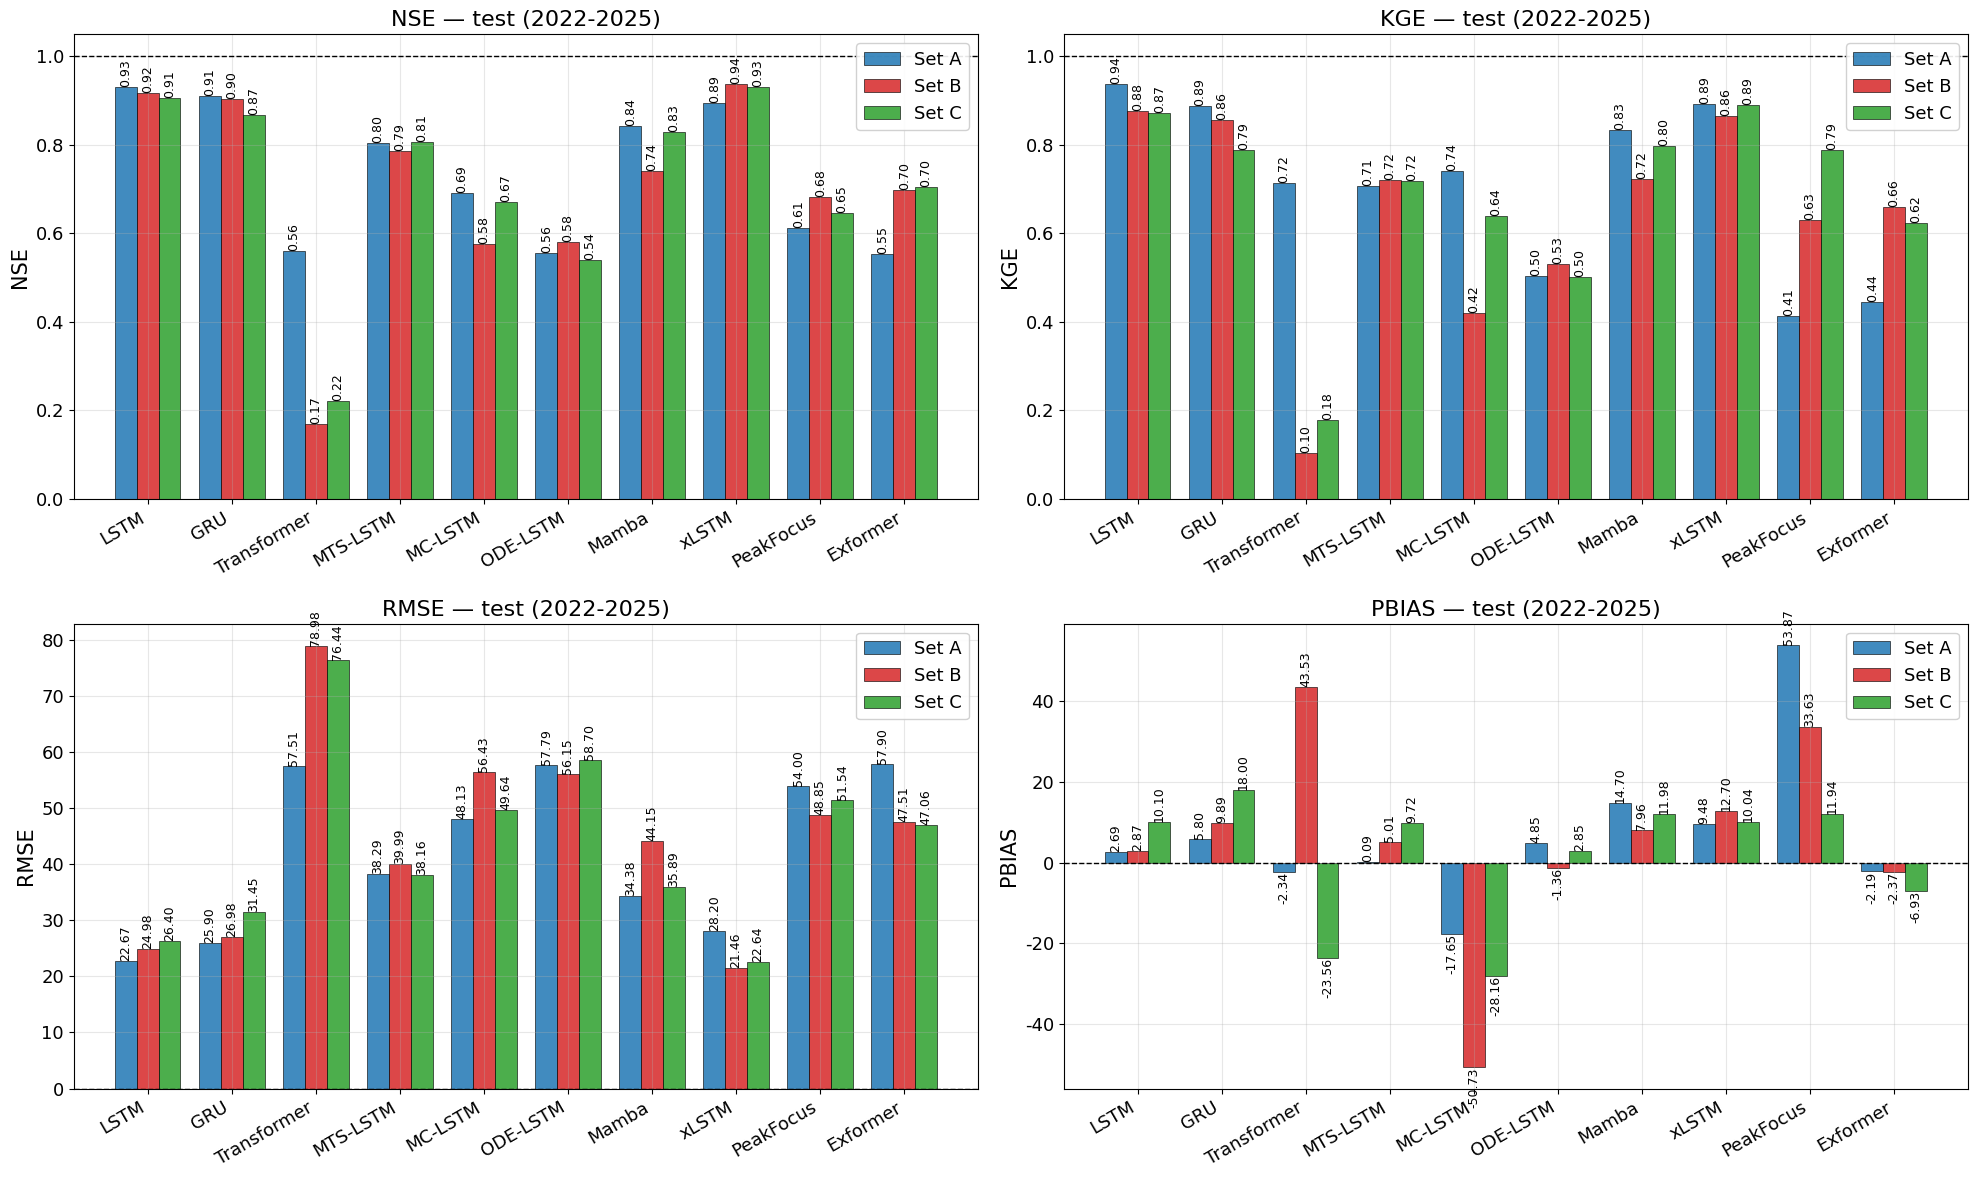

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(20, 12))
for ax, metric in zip(axes.ravel(), ["NSE", "KGE", "RMSE", "PBIAS"]):
    common.plot_metric_bars(results, metric, period="test", ax=ax)
    if metric in ("NSE", "KGE"):
        ax.set_ylim(max(-0.2, ax.get_ylim()[0]), 1.05)
fig.tight_layout()
common.save_fig(fig, "cmp_bars_test")
plt.show()

### 2.3 일반화: 학습 NSE 대 테스트 NSE

1:1 선에서 아래로 멀수록 학습 기간에 비해 테스트 기간 성능이 떨어진 것(과적합 또는 기간 간 수문특성 차이)입니다.
검증 NSE 를 x축으로 바꾸면 "검증으로 고른 모델이 테스트에서도 좋은가"를 볼 수 있습니다.

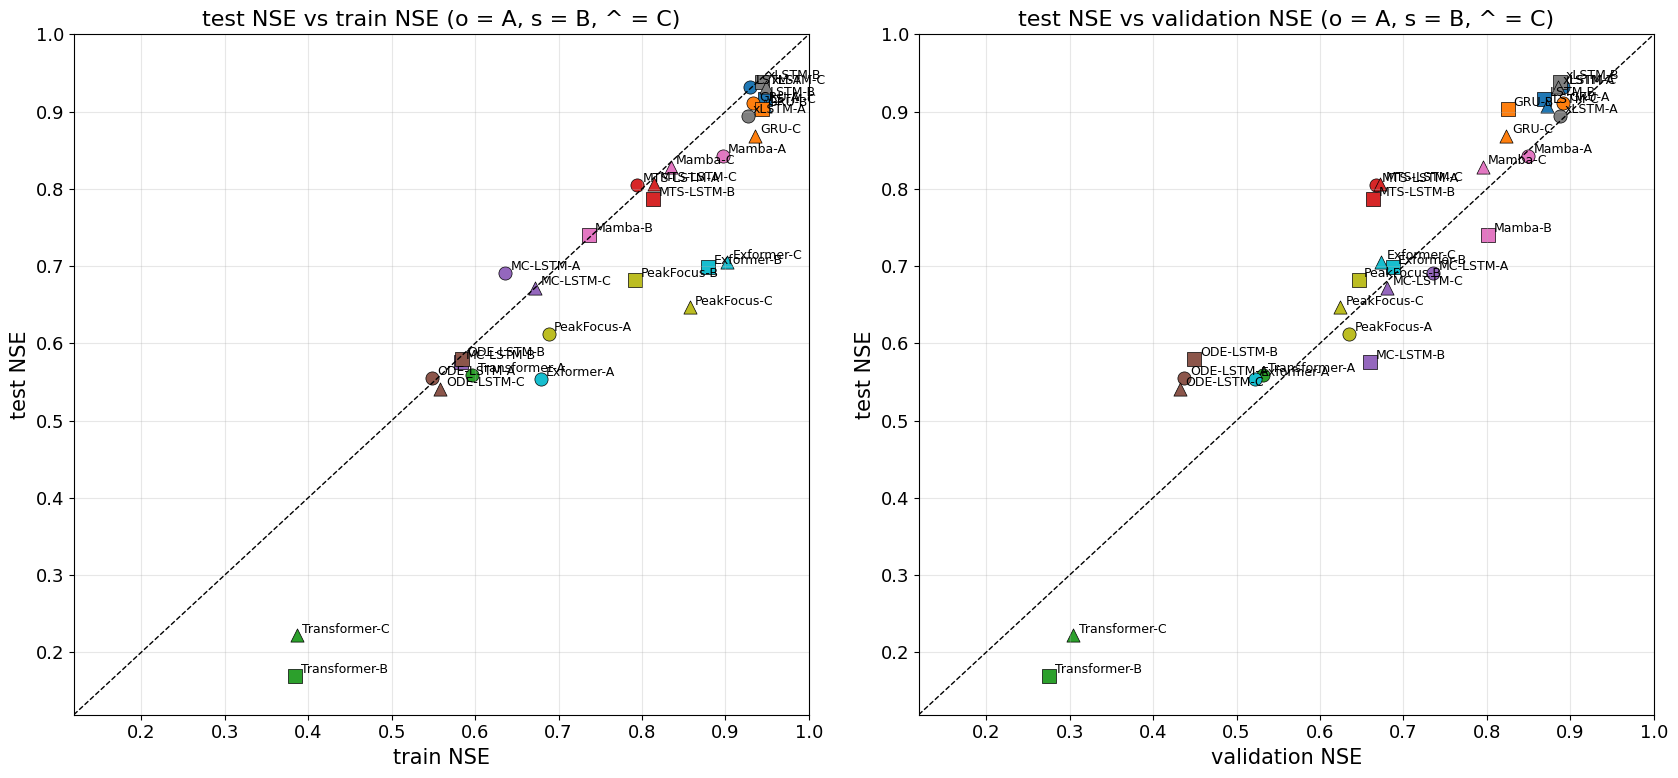

In [7]:
wide = results.pivot_table(index=["model", "model_name", "set"], columns="period", values="NSE", observed=True).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(17, 8))
for ax, xcol in zip(axes, ["train", "validation"]):
    for _, r in wide.iterrows():
        ax.scatter(r[xcol], r["test"], color=MODEL_COLOR[r["model"]], marker={"A": "o", "B": "s", "C": "^"}[r["set"]], s=90,
                   edgecolor="black", lw=0.5)
        ax.annotate(f"{r['model_name']}-{r['set']}", (r[xcol], r["test"]), fontsize=9, xytext=(4, 2), textcoords="offset points")
    lo = max(0, min(wide[xcol].min(), wide["test"].min()) - 0.05)
    ax.plot([lo, 1], [lo, 1], "k--", lw=1)
    ax.set_xlim(lo, 1)
    ax.set_ylim(lo, 1)
    ax.set_xlabel(f"{xcol} NSE")
    ax.set_ylabel("test NSE")
    ax.set_title(f"test NSE vs {xcol} NSE (o = A, s = B, ^ = C)")
fig.tight_layout()
common.save_fig(fig, "cmp_generalization")
plt.show()

## 3. 학습곡선 비교

각 모델의 **테스트 NSE 가 가장 높은 입력세트** 의 검증 NSE 추이입니다. 수렴 속도(몇 epoch 만에 안정되는가)와 안정성(흔들림)을 비교합니다.
MC-LSTM 은 손실이 mm/h 단위라 loss 축에서는 비교할 수 없으므로 검증 NSE 만 봅니다.

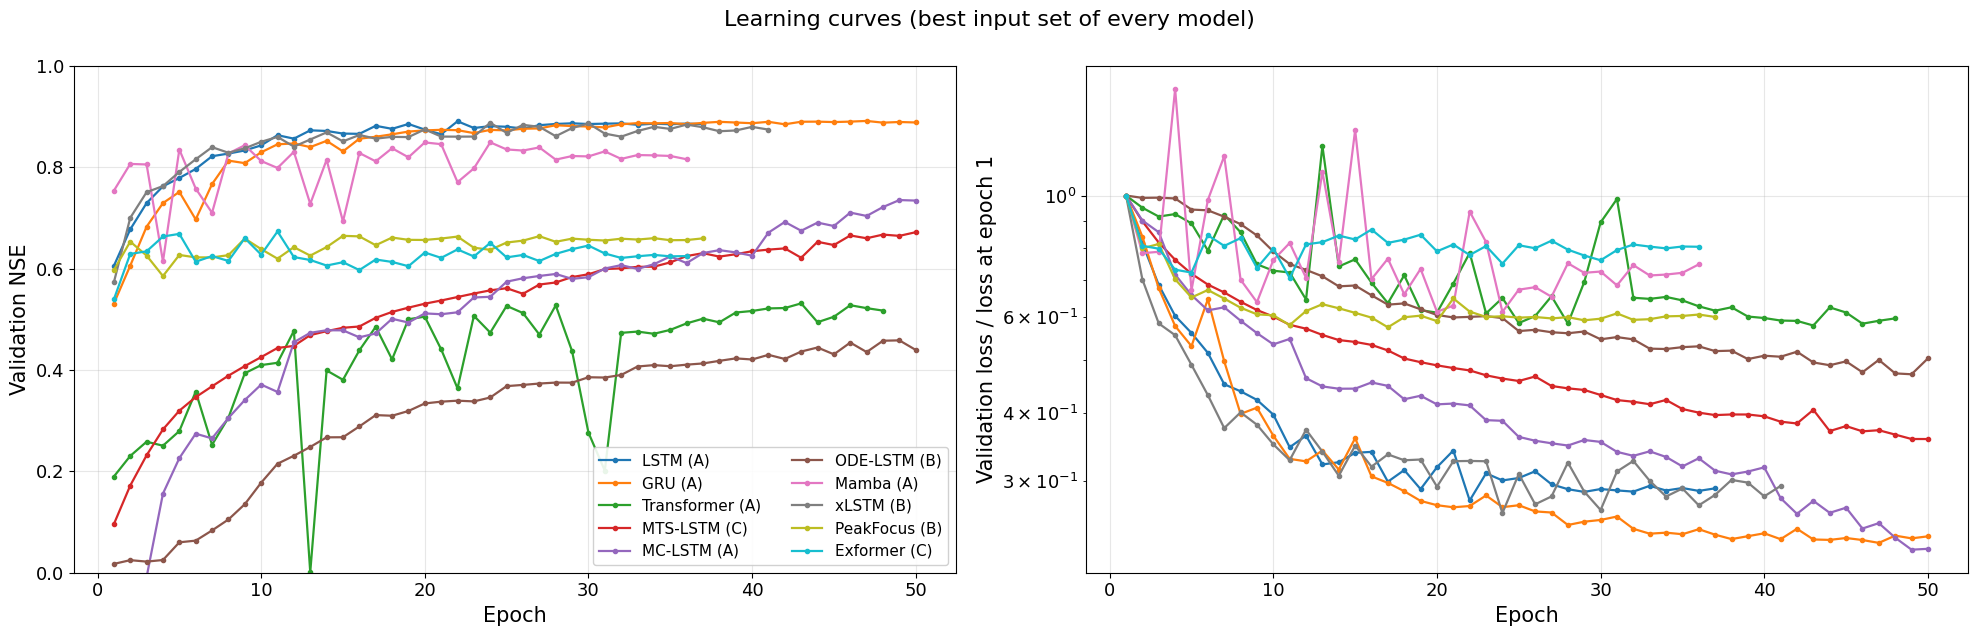

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(20, 6.5))
for m in models:
    h = common.load_saved_history(m, best_set[m])
    axes[0].plot(h.index, h["NSE"], label=label[m], color=MODEL_COLOR[m], marker="o", ms=3)
    axes[1].plot(h.index, h["val_loss"] / h["val_loss"].iloc[0], label=label[m], color=MODEL_COLOR[m], marker="o", ms=3)
axes[0].set_ylabel("Validation NSE")
axes[0].set_ylim(0, 1)
axes[1].set_ylabel("Validation loss / loss at epoch 1")
axes[1].set_yscale("log")
for ax in axes:
    ax.set_xlabel("Epoch")
axes[0].legend(loc="lower right", ncol=2, fontsize=11)
fig.suptitle("Learning curves (best input set of every model)", fontsize=16)
fig.tight_layout()
common.save_fig(fig, "cmp_learning_curves")
plt.show()

## 4. 테스트 기간 수문곡선 비교

연도별 패널에 모든 모델(각각 최적 입력세트)을 겹쳐 그립니다. 선이 많으므로 전체 모양(계절성, 홍수기 반응, 건기 수준)을 보는 용도이고,
사건별 세부 비교는 `" + NB_PEAKS + "` 에서 합니다.

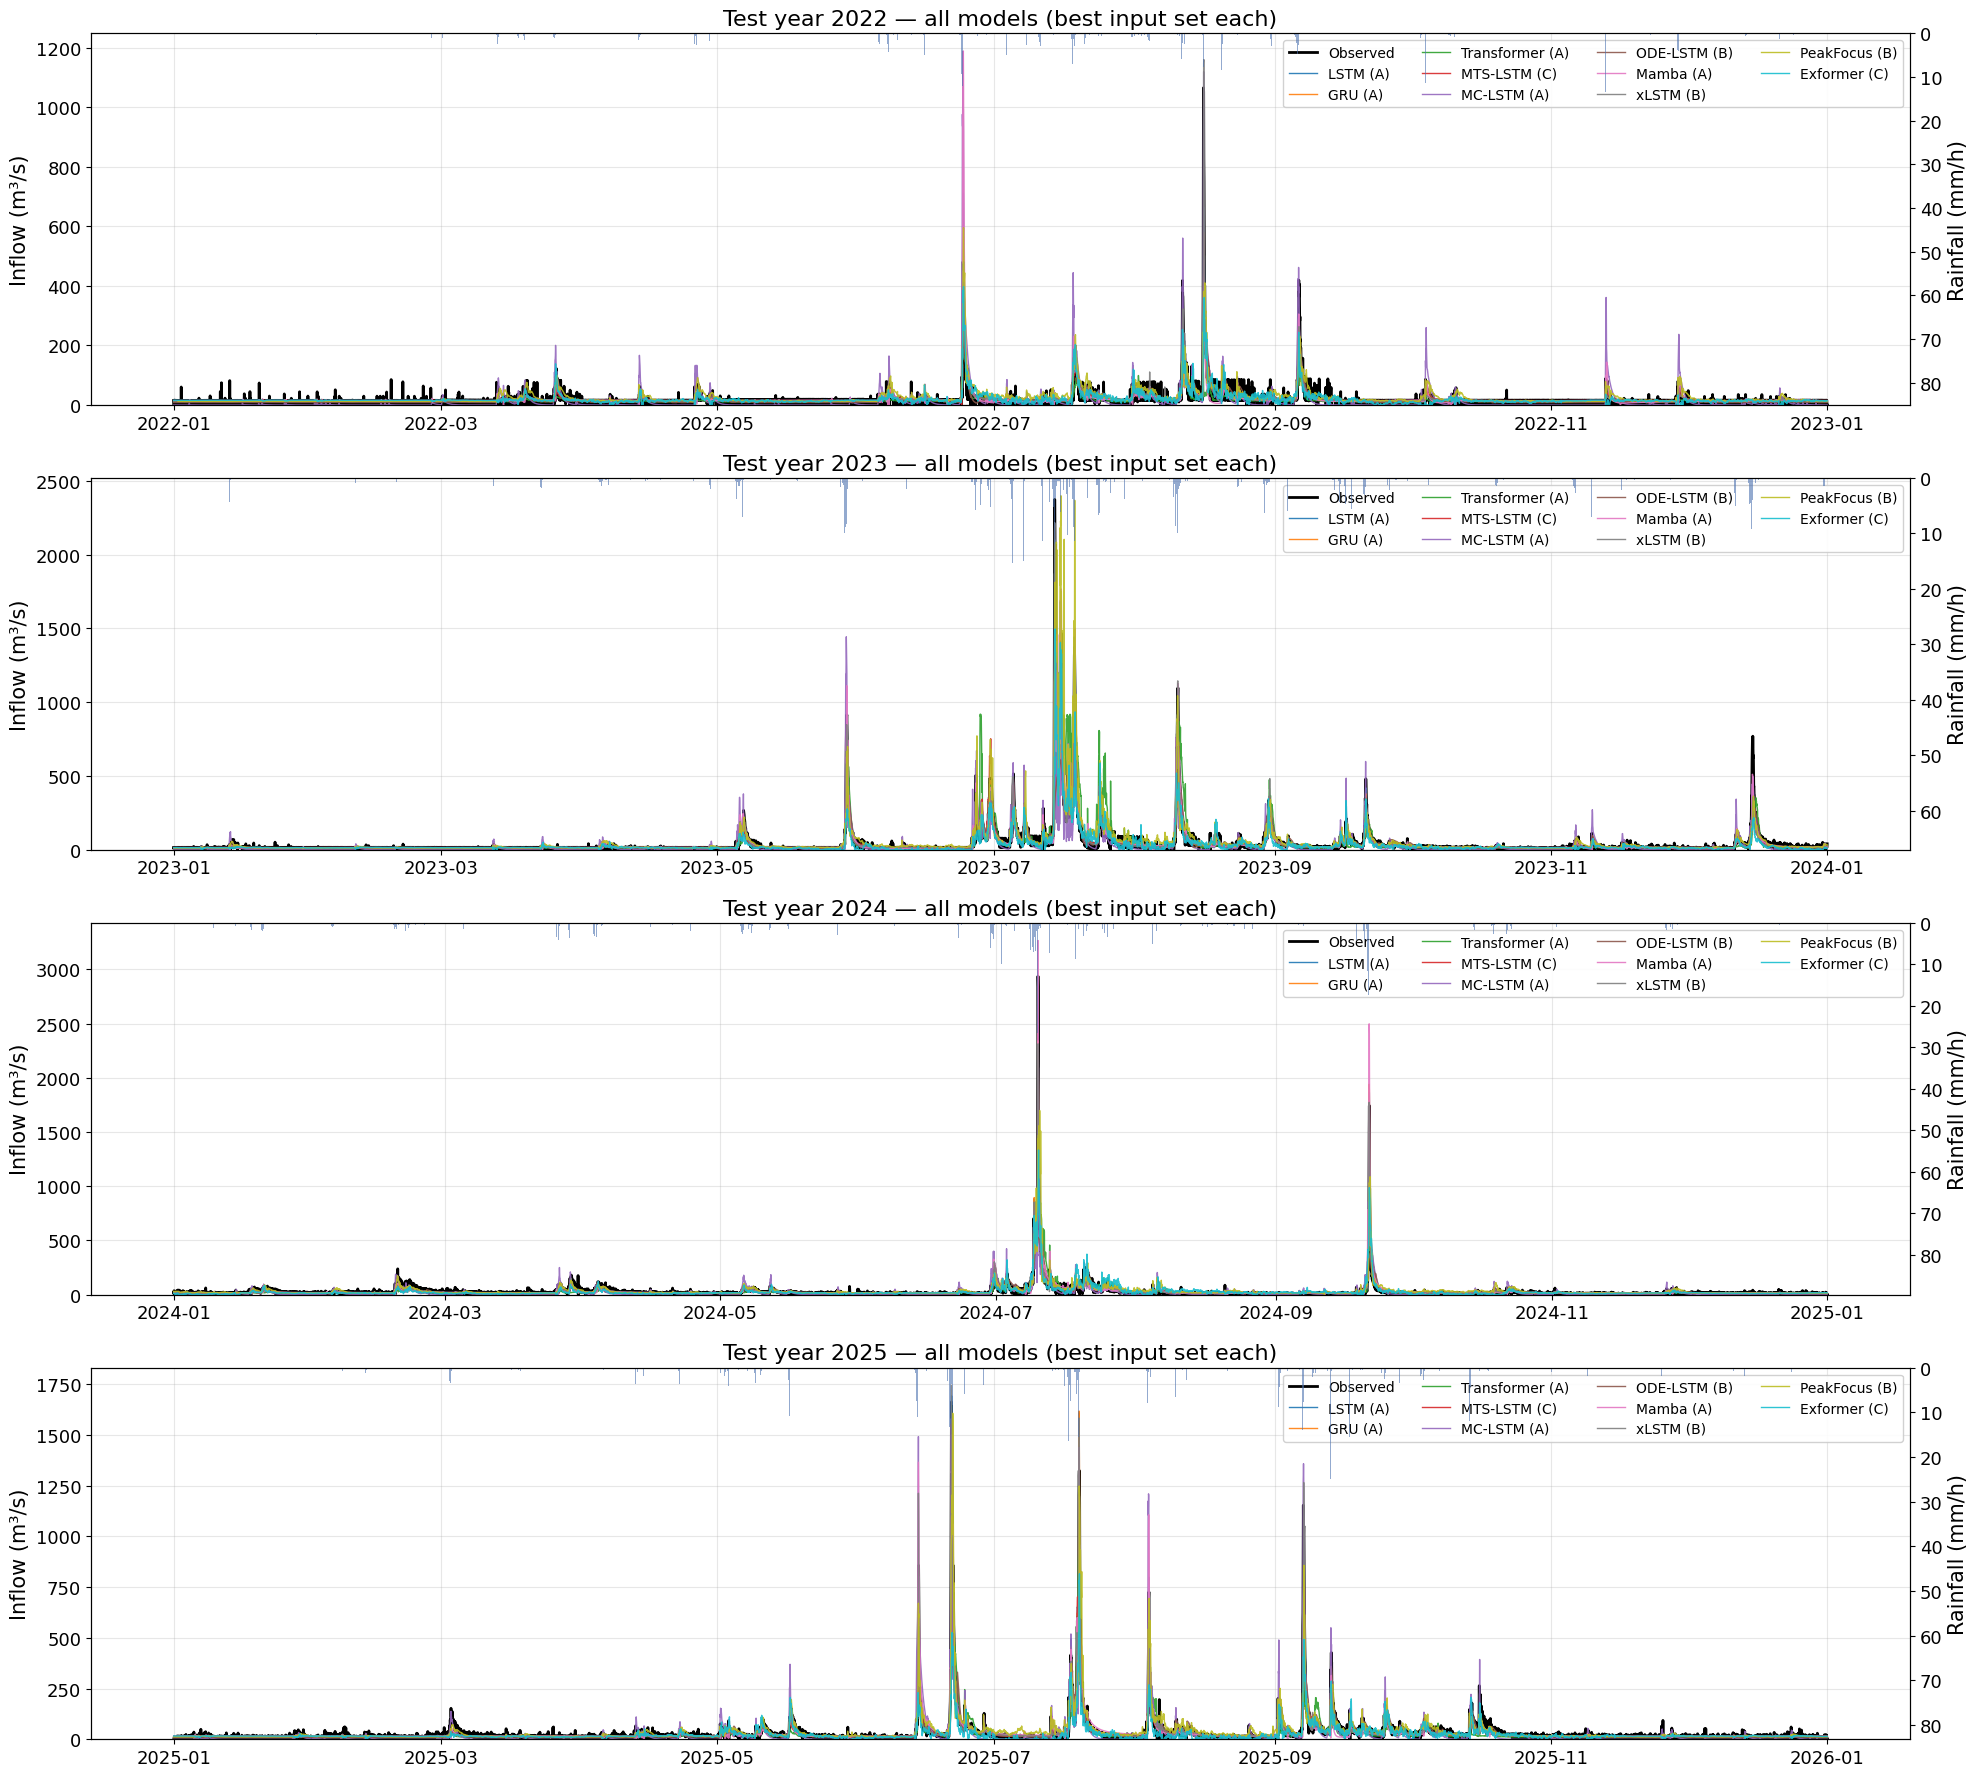

In [9]:
obs_all = preds[(models[0], "A")]["obs"]
fig, axes = plt.subplots(4, 1, figsize=(20, 18))
for ax, year in zip(axes, range(2022, 2026)):
    start, end = f"{year}-01-01", f"{year}-12-31 23:00"
    common.plot_hydrograph(obs_all.loc[start:end], {label[m]: preds[(m, best_set[m])].loc[start:end, "sim"] for m in models},
                           rain=rain.loc[start:end], title=f"Test year {year} — all models (best input set each)", ax=ax,
                           colors={label[m]: MODEL_COLOR[m] for m in models}, sim_lw=1.0, obs_lw=2.0)
    ax.legend(loc="upper right", ncol=4, fontsize=10)
fig.tight_layout()
common.save_fig(fig, "cmp_hydrograph_test")
plt.show()

### 4.1 유량지속곡선 비교 (테스트 기간)

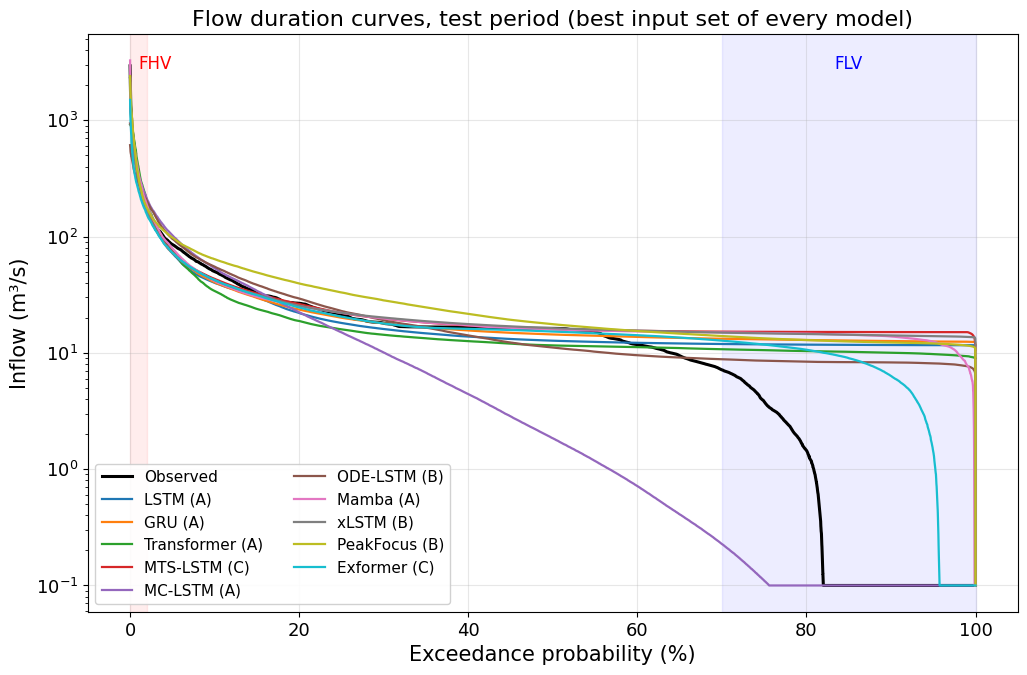

In [10]:
test_mask = preds[(models[0], "A")]["period"] == "test"
fig, ax = plt.subplots(figsize=(12, 7.5))
common.plot_fdc(obs_all[test_mask], {label[m]: preds[(m, best_set[m])].loc[test_mask, "sim"] for m in models},
                title="Flow duration curves, test period (best input set of every model)",
                colors={label[m]: MODEL_COLOR[m] for m in models}, ax=ax)
ax.legend(loc="lower left", ncol=2, fontsize=11)
common.save_fig(fig, "cmp_fdc_test")
plt.show()

## 5. 연도별 · 월별 성능

### 5.1 연도별 NSE 히트맵 (각 모델의 최적 입력세트)

세로줄로 특정 해(예: 2020년 대홍수가 있는 검증 기간, 2023·2024년 테스트 기간)에 모든 모델이 함께 나빠지는지, 아니면 특정 모델만 나빠지는지
를 볼 수 있습니다.

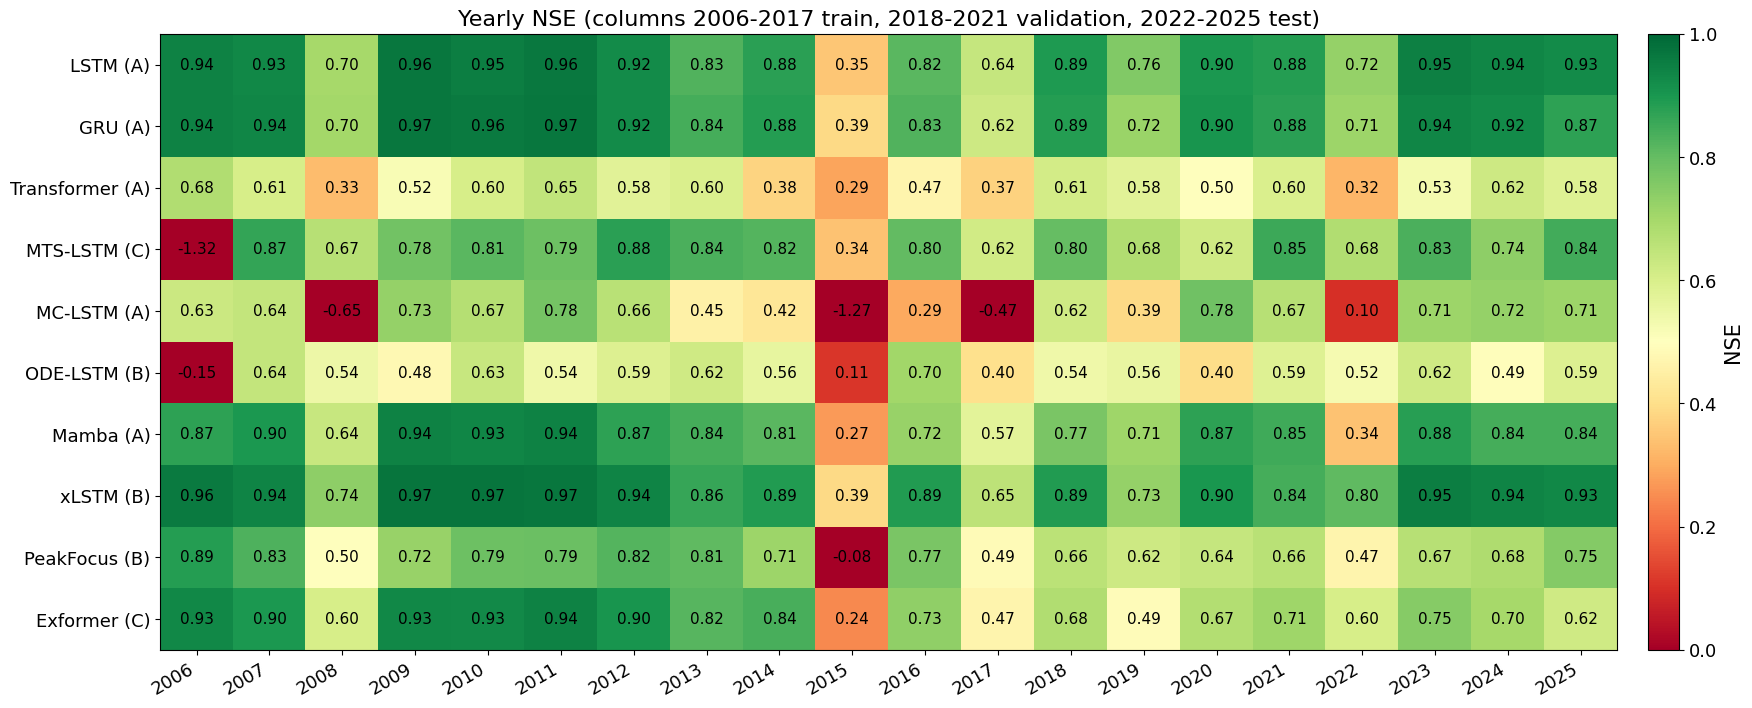

In [11]:
yearly = pd.DataFrame({label[m]: common.yearly_metrics(preds[(m, best_set[m])])["NSE"] for m in models}).T
fig, ax = plt.subplots(figsize=(20, 8))
common.plot_heatmap(yearly, title="Yearly NSE (columns 2006-2017 train, 2018-2021 validation, 2022-2025 test)", vmin=0, vmax=1,
                    ax=ax, cbar_label="NSE")
common.save_fig(fig, "cmp_yearly_nse")
plt.show()

### 5.2 월별 총량 편향 (테스트 기간)

월별 PBIAS 는 계절별 체계적 편향(예: 건기 과대, 홍수기 과소)을 보여 줍니다.

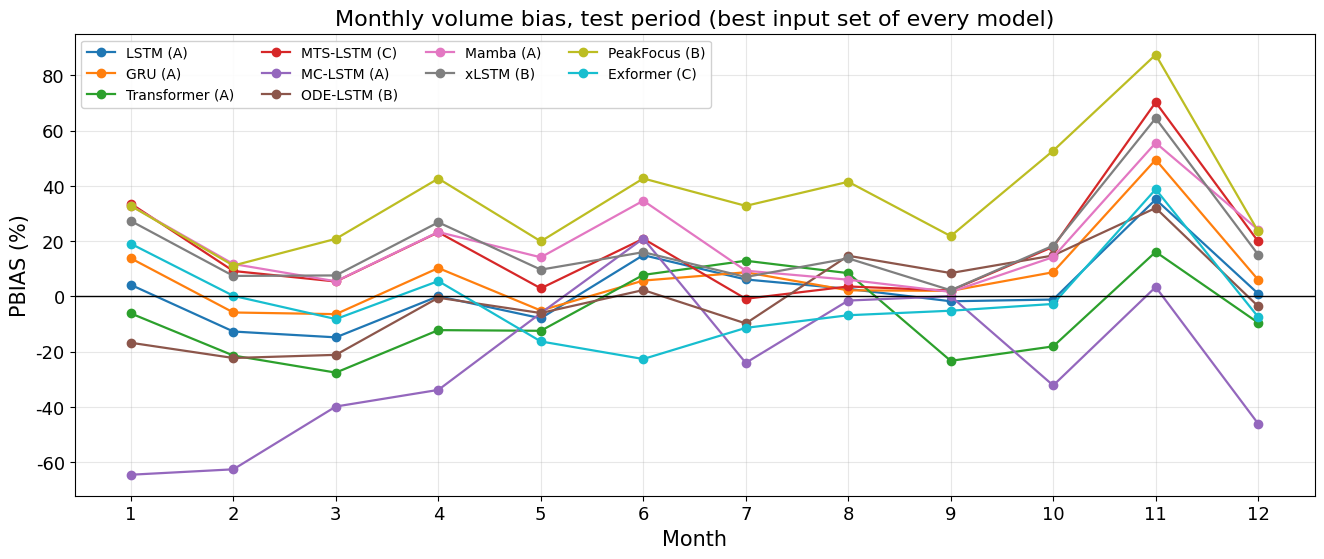

In [12]:
fig, ax = plt.subplots(figsize=(16, 6))
for m in models:
    df = preds[(m, best_set[m])]
    mm = common.monthly_metrics(df[df["period"] == "test"])
    ax.plot(mm.index, mm["PBIAS"], label=label[m], color=MODEL_COLOR[m], marker="o")
ax.axhline(0, color="black", lw=1)
ax.set_xticks(range(1, 13))
ax.set_xlabel("Month")
ax.set_ylabel("PBIAS (%)")
ax.set_title("Monthly volume bias, test period (best input set of every model)")
ax.legend(ncol=4, fontsize=10)
common.save_fig(fig, "cmp_monthly_pbias")
plt.show()

## 6. 입력세트의 효과

유역평균 강우(A) 대비 관측소별 강우(B)와 둘을 합친 경우(C)의 테스트 NSE 변화량입니다. 양수면 관측소별 강우가 도움이 된 것입니다.
7개 관측소 평균과 유역평균의 상관이 0.998 로 매우 높아 정보 이득은 **공간 분포**(어느 관측소에 비가 왔는가)에서만 나옵니다.

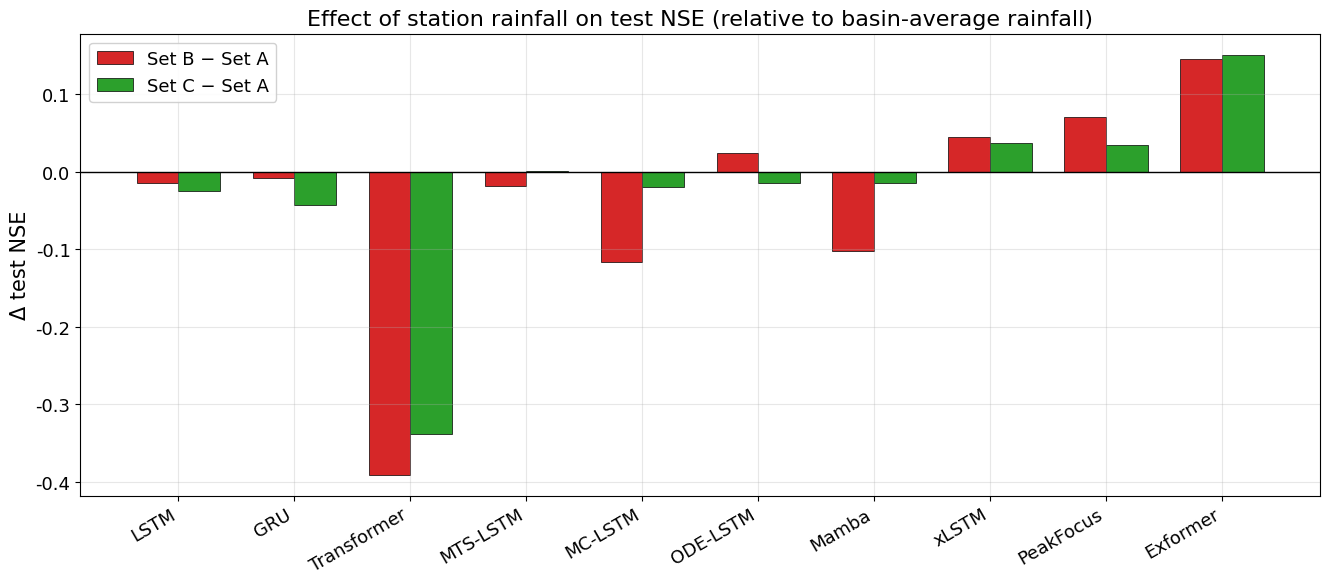

,B − A,C − A
model_name,,
LSTM,-0.015,-0.024
GRU,-0.008,-0.042
Transformer,-0.390,-0.338
MTS-LSTM,-0.018,0.001
MC-LSTM,-0.116,-0.020
ODE-LSTM,0.025,-0.014
Mamba,-0.102,-0.014
xLSTM,0.045,0.038
PeakFocus,0.070,0.034


In [13]:
t = results[results["period"] == "test"].pivot_table(index="model_name", columns="set", values="NSE", observed=True)
delta = pd.DataFrame({"B − A": t["B"] - t["A"], "C − A": t["C"] - t["A"]})
fig, ax = plt.subplots(figsize=(16, 6))
x = np.arange(len(delta))
ax.bar(x - 0.18, delta["B − A"], 0.36, label="Set B − Set A", color=SET_COLOR["B"], edgecolor="black", lw=0.5)
ax.bar(x + 0.18, delta["C − A"], 0.36, label="Set C − Set A", color=SET_COLOR["C"], edgecolor="black", lw=0.5)
ax.axhline(0, color="black", lw=1)
ax.set_xticks(x)
ax.set_xticklabels(delta.index, rotation=30, ha="right")
ax.set_ylabel("Δ test NSE")
ax.set_title("Effect of station rainfall on test NSE (relative to basin-average rainfall)")
ax.legend()
common.save_fig(fig, "cmp_input_set_effect")
plt.show()
display(delta.round(3))

## 7. 정확도 대 계산 비용

x축: epoch당 학습 시간(로그), y축: 테스트 NSE, 원 크기: 파라미터 수. 왼쪽 위가 "싸고 좋은" 모델입니다.

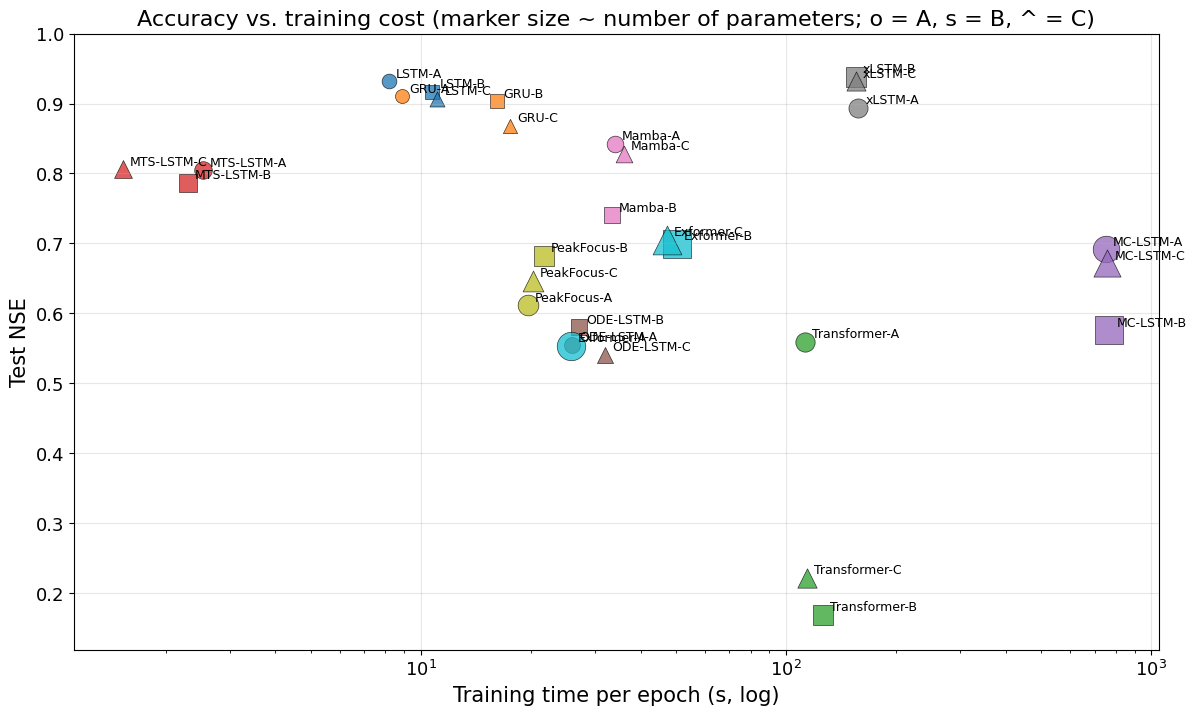

In [14]:
sub = results[results["period"] == "test"]
fig, ax = plt.subplots(figsize=(14, 8))
for _, r in sub.iterrows():
    ax.scatter(r["epoch_time_mean_s"], r["NSE"], s=30 + 400 * np.sqrt(r["n_parameters"] / sub["n_parameters"].max()),
               color=MODEL_COLOR[r["model"]], alpha=0.75, edgecolor="black", lw=0.5,
               marker={"A": "o", "B": "s", "C": "^"}[r["set"]])
    ax.annotate(f"{r['model_name']}-{r['set']}", (r["epoch_time_mean_s"], r["NSE"]), fontsize=9, xytext=(5, 3), textcoords="offset points")
ax.set_xscale("log")
ax.set_xlabel("Training time per epoch (s, log)")
ax.set_ylabel("Test NSE")
ax.set_ylim(max(0, sub["NSE"].min() - 0.05), 1)
ax.set_title("Accuracy vs. training cost (marker size ~ number of parameters; o = A, s = B, ^ = C)")
common.save_fig(fig, "cmp_accuracy_vs_cost")
plt.show()

## 8. 종합 순위

테스트 기간의 NSE, KGE, RMSE, |PBIAS|, |FHV| 다섯 지표에 대한 순위의 평균입니다(각 모델의 최적 입력세트 기준과 세트별 기준 모두 제시).
순위 평균이 작을수록 종합적으로 좋습니다.

In [15]:
sub = results[results["period"] == "test"].copy()
sub["absPBIAS"] = sub["PBIAS"].abs()
sub["absFHV"] = sub["FHV"].abs()
rank_cols = {"NSE": False, "KGE": False, "RMSE": True, "absPBIAS": True, "absFHV": True}
ranks = pd.DataFrame({c: sub[c].rank(ascending=asc) for c, asc in rank_cols.items()})
sub["mean_rank"] = ranks.mean(axis=1)
ranking = sub.sort_values("mean_rank")[["model_name", "set", "NSE", "KGE", "RMSE", "PBIAS", "FHV", "mean_rank"]].reset_index(drop=True)
ranking.index += 1
display(ranking.round(3))
ranking.round(3).to_csv(common.RESULTS_DIR / "comparison_ranking_test.csv")

best_rows = sub.loc[sub.groupby("model", observed=True)["NSE"].idxmax()].sort_values("NSE", ascending=False)
display(best_rows[["model_name", "set", "NSE", "KGE", "RMSE", "PBIAS", "FHV", "FLV", "epoch_time_mean_s", "n_parameters"]].round(3).reset_index(drop=True))

,model_name,set,NSE,KGE,RMSE,PBIAS,FHV,mean_rank
1,LSTM,A,0.932,0.937,22.668,2.692,-1.381,3.6
2,xLSTM,C,0.932,0.891,22.644,10.043,-1.071,5.6
3,xLSTM,A,0.894,0.892,28.196,9.477,0.449,6.8
4,LSTM,B,0.917,0.877,24.977,2.874,-7.796,7.0
5,GRU,A,0.911,0.887,25.904,5.799,-6.257,7.2
6,xLSTM,B,0.939,0.865,21.465,12.699,-2.389,7.4
7,LSTM,C,0.907,0.871,26.405,10.095,-0.748,7.8
8,GRU,B,0.903,0.855,26.985,9.893,-2.502,9.2
9,Mamba,A,0.843,0.834,34.380,14.697,3.848,12.0
10,GRU,C,0.868,0.789,31.450,17.996,-1.676,12.0


,model_name,set,NSE,KGE,RMSE,PBIAS,FHV,FLV,epoch_time_mean_s,n_parameters
0,xLSTM,B,0.939,0.865,21.465,12.699,-2.389,-187.148,155.100,64329
1,LSTM,A,0.932,0.937,22.668,2.692,-1.381,99.844,8.194,17217
2,GRU,A,0.911,0.887,25.904,5.799,-6.257,96.700,8.898,12929
3,Mamba,A,0.843,0.834,34.380,14.697,3.848,-184.721,33.943,32833
4,MTS-LSTM,C,0.806,0.718,38.158,9.721,-14.550,-188.069,1.531,46338
5,Exformer,C,0.705,0.625,47.062,-6.933,-30.224,-137.636,47.086,402960
6,MC-LSTM,A,0.692,0.741,48.125,-17.652,-6.375,-297.950,752.653,283008
7,PeakFocus,B,0.682,0.630,48.851,33.625,6.518,-172.457,21.778,95066
8,ODE-LSTM,B,0.580,0.532,56.151,-1.360,-33.237,94.167,27.143,27073
9,Transformer,A,0.559,0.715,57.509,-2.343,0.003,97.827,113.000,67137


### 8.1 자동 생성 요약

In [16]:
lines = []
top = best_rows.iloc[0]
lines.append(f"- 테스트 NSE 최고: **{top['model_name']} (Set {top['set']})** NSE {top['NSE']:.3f}, KGE {top['KGE']:.3f}, RMSE {top['RMSE']:.1f} m³/s.")
baseline = sub[(sub['model'] == 'lstm')].sort_values('NSE', ascending=False).iloc[0]
lines.append(f"- 기준 LSTM 최고 세트 (Set {baseline['set']}): NSE {baseline['NSE']:.3f}, KGE {baseline['KGE']:.3f}.")
better = best_rows[best_rows["NSE"] > baseline["NSE"] + 0.01]["model_name"].tolist()
worse = best_rows[best_rows["NSE"] < baseline["NSE"] - 0.01]["model_name"].tolist()
lines.append(f"- LSTM 보다 NSE 0.01 이상 높은 모델: {', '.join(str(x) for x in better) if better else '없음'}; 낮은 모델: {', '.join(str(x) for x in worse) if worse else '없음'}.")
pos = delta.mean()
lines.append(f"- 입력세트 효과(테스트 NSE 변화량의 모델 평균): B−A {pos['B − A']:+.3f}, C−A {pos['C − A']:+.3f}; "
             f"B 또는 C 가 A 보다 좋은 모델 수 {(delta.max(axis=1) > 0).sum()} / {len(delta)}.")
fast = sub.sort_values('epoch_time_mean_s').iloc[0]
slow = sub.sort_values('epoch_time_mean_s').iloc[-1]
lines.append(f"- epoch당 학습 시간: 최단 {fast['model_name']} {fast['epoch_time_mean_s']:.0f} s, 최장 {slow['model_name']} {slow['epoch_time_mean_s']:.0f} s "
             f"({slow['epoch_time_mean_s'] / fast['epoch_time_mean_s']:.0f}배).")
gap = (wide["train"] - wide["test"]).groupby(wide["model_name"], observed=True).mean().sort_values()
lines.append(f"- 학습−테스트 NSE 차이(세트 평균)가 가장 작은 모델: {gap.index[0]} ({gap.iloc[0]:+.3f}), 가장 큰 모델: {gap.index[-1]} ({gap.iloc[-1]:+.3f}).")
display(Markdown("\n".join(lines)))

- 테스트 NSE 최고: **xLSTM (Set B)** NSE 0.939, KGE 0.865, RMSE 21.5 m³/s.
- 기준 LSTM 최고 세트 (Set A): NSE 0.932, KGE 0.937.
- LSTM 보다 NSE 0.01 이상 높은 모델: 없음; 낮은 모델: GRU, Mamba, MTS-LSTM, Exformer, MC-LSTM, PeakFocus, ODE-LSTM, Transformer.
- 입력세트 효과(테스트 NSE 변화량의 모델 평균): B−A -0.036, C−A -0.023; B 또는 C 가 A 보다 좋은 모델 수 5 / 10.
- epoch당 학습 시간: 최단 MTS-LSTM 2 s, 최장 MC-LSTM 768 s (502배).
- 학습−테스트 NSE 차이(세트 평균)가 가장 작은 모델: MC-LSTM (-0.016), 가장 큰 모델: Exformer (+0.167).

## 9. 해석

### 9.1 전체 순위와 모델군별 특성

테스트 기간(2022–2025) NSE 기준으로 10개 모델은 뚜렷한 **세 집단**으로 나뉜다.

| 집단 | 모델 (최적 입력세트, 테스트 NSE) | 특징 |
|---|---|---|
| 상위 (NSE ≥ 0.9) | xLSTM (B, 0.939), LSTM (A, 0.932), GRU (A, 0.911) | 게이트 순환 구조. 학습–테스트 차이 0.01–0.04, 첨두 시각 오차 ~1 h |
| 중위 (0.65–0.85) | Mamba (A, 0.843), MTS-LSTM (C, 0.806), Exformer (C, 0.705), MC-LSTM (A, 0.692), PeakFocus (B, 0.682) | 각각 다른 이유로 제한: 학습 불안정(Mamba), 갱신 횟수 부족(MTS-LSTM), 상태 없는 구조(Exformer, PeakFocus), 질량보존 제약(MC-LSTM) |
| 하위 (< 0.6) | ODE-LSTM (B, 0.580), Transformer (A, 0.559) | 시간 강우 첨두가 평균화되거나(ODE-LSTM) 학습이 수렴하지 않음(Transformer) |

다섯 지표(NSE, KGE, RMSE, |PBIAS|, |FHV|) 순위 평균으로는 **LSTM-A 가 1위(3.6)**, xLSTM-C (5.6), xLSTM-A (6.8), LSTM-B (7.0), GRU-A (7.2)
순이다. xLSTM-B 는 NSE 가 가장 높지만 총량 과대 추정(PBIAS +12.7%) 때문에 종합 순위는 6위다. 즉 **NSE 만으로는 xLSTM, 편향까지 고려하면
LSTM** 이 가장 균형 잡힌 모델이다.

### 9.2 입력세트의 효과: 모델 구조에 따라 방향이 다르다

- **LSTM, GRU, Mamba**: 유역평균 강우(A)가 최선. 관측소별 강우(B, C)는 학습 NSE 를 올리지만 테스트 NSE 를 0.01–0.10 낮추고 총량 과대 추정을
  만든다. 7개 관측소 평균과 유역평균의 상관이 0.998 이므로 추가되는 정보는 공간 분포뿐인데, 단일 유역·12년 학습 자료로는 이를 일반화 가능하게
  배우기 어렵다.
- **xLSTM, Exformer, PeakFocus**: 관측소별 강우가 **도움**이 된다(xLSTM A 0.894 → B 0.939; Exformer 0.55 → 0.70; PeakFocus 0.61 → 0.68).
  행렬 메모리(xLSTM)와 채널 독립 인코더(Exformer)는 채널이 늘수록 표현 용량이 늘어나는 구조다.
- **MTS-LSTM, ODE-LSTM, MC-LSTM, Transformer**: 세트 간 차이가 작거나(±0.04) 입력이 늘면 나빠진다(Transformer 0.56 → 0.17).
- 모델 평균으로는 B−A, C−A 모두 음수에 가깝고, "관측소별 강우가 유역평균보다 낫다"는 가설은 **xLSTM 에서만** 분명히 지지된다.

### 9.3 일반화(학습 대 테스트)

- 순환 모델(LSTM, GRU, xLSTM)은 학습 NSE 0.93–0.95, 테스트 0.87–0.94 로 차이가 작다. 검증 기간(2018–2021, 2020년 대홍수 포함) NSE 가
  0.82–0.89 로 테스트보다 낮은 것은 학습에 없는 크기의 홍수(4,395 m³/s)가 검증 기간에 있기 때문이며, 테스트 기간 최대(2,937 m³/s)는 학습 범위
  안이다.
- Exformer (학습 0.90 → 테스트 0.70) 와 PeakFocus (0.86 → 0.65) 는 **과적합**이 뚜렷하고 검증 loss 최소가 9–21 epoch 에서 나타난다.
- Transformer 는 학습 NSE 자체가 0.4–0.6 으로 **과소적합**, MC-LSTM 과 MTS-LSTM 은 50 epoch 에서도 **수렴 전**이다(최적 epoch 49–50).

### 9.4 저유량 바닥값과 FLV

관측 유입량의 16% 가 0 이고 저수지 수지식 역산의 특성상 건기 자료는 10 m³/s 미만에서 불연속적이다. 모든 모델이 0 을 내지 못하고 10–15 m³/s 의
바닥값을 유지하므로 FLV(저유량 체적 편향)는 ±100% 를 넘는 극단값이 되어 모델 간 비교 지표로는 부적합하다. MC-LSTM 만 질량보존 때문에 바닥값이
낮고 그 결과 FLV 가 큰 음수, PBIAS 가 −18 ~ −51% 로 나타난다. 0 관측값을 결측으로 처리하거나 로그 변환 목표를 쓰는 것이 후속 과제다.

### 9.5 계산 비용

| 구분 | epoch 당 시간 (s) | LSTM 대비 | 비고 |
|---|---|---|---|
| LSTM / GRU | 8–18 | 1× | cuDNN 커널 |
| MTS-LSTM | 2–3 | 0.3× | 하루 1 샘플(갱신 횟수 1/24) |
| PeakFocus / ODE-LSTM / Exformer / Mamba | 20–50 | 2.5–6× | |
| Transformer | 113–126 | ~14× | 720² 주의 |
| xLSTM | 155–158 | ~19× | GPU 21 GB, 단독 실행 필요 |
| MC-LSTM | 750–770 | ~90× | 파이썬 루프 720 단계, run 당 11 h |

정확도 대비 비용에서 **LSTM 이 압도적**이며(8 s/epoch, NSE 0.93), xLSTM 은 NSE +0.007 을 얻기 위해 19배의 시간과 10배의 GPU 메모리를 쓴다.
MC-LSTM 과 Transformer 는 비용과 정확도 모두 불리하다.

### 9.6 구현 과정에서 발견한 라이브러리 문제 (재현성 참고)

1. `mamba.py` 가 `InputLayer` 출력([seq, batch, feat])을 전치하지 않아 배치 축을 시간 축으로 처리 → 수정 후 NSE 0.13 → 0.84.
2. `Config` 가 `mamba_d_state` 등 Mamba 키를 읽지 못함(검증기는 `mamba_*` 만 허용, 속성은 `d_state` 를 읽음) → 수정.
3. PeakFocus 이식본의 입력창 정규화가 역정규화 없이 적용되어 강우 크기 정보 상실 → `peakfocus_instance_norm` 옵션 추가(기본 false), NSE 0.2 → 0.65.

이 수정 없이 얻은 결과(`runs/_buggy_mamba_layout/`, `runs/_instnorm_peakfocus/`)는 비교에서 제외했다.


## 10. Future work: 하이퍼파라미터 튜닝

본 비교는 **모든 모델에 같은 학습 설정**(hidden 64, Adam 1e-3, batch 256, seq 720, epoch 30–50, early stopping) 을 적용한 것으로,
각 모델이 낼 수 있는 최고 성능이 아니라 "같은 예산에서의 기본 성능" 을 비교한 것입니다. 후속 연구에서 다룰 항목:

1. **모델별 탐색 공간**: 순환 모델은 `hidden_size`(32–256), `output_dropout`, `seq_length`(168–2160 h); 트랜스포머 계열은 층 수·헤드 수·`d_model`·
   위치 인코딩; Mamba 는 `d_state`·`expand`; xLSTM 은 블록 수와 sLSTM 위치; PeakFocus 는 첨두 라벨 임계와 손실 가중치; Exformer 는 패치 크기와
   극한 임계.
2. **학습률·배치·스케줄**: 학습률(1e-4 ~ 5e-3), 배치(64–512), cosine / OneCycle 스케줄, 학습률 워밍업(트랜스포머 계열에 특히 중요).
3. **손실 함수**: MSE 외에 NSE 손실(`NSE`), 첨두 가중 손실, 로그 변환 목표 — 저유량 과대·첨두 과소 편향에 직접 영향.
4. **입력 확장**: 기온·증발산·댐 방류·저수위 등 추가 변수, 정적 속성(다유역 학습 시).
5. **앙상블과 시드**: 시드 3–5개 평균(`nh-results-ensemble`)으로 모델 간 차이가 시드 변동보다 큰지 검정.
6. **탐색 방법**: Optuna / Ray Tune 등으로 검증 NSE 를 목적함수로 한 베이지안 탐색을 모델별 동일 시도 횟수(예: 30회)로 수행하고,
   튜닝 전후의 순위 변화를 보고.
